# 04 · Clustering

Two k-means analyses from the course:

1. **Agents** — each of the 868 agent-tariff series summarised by six numbers (size, seasonality, volatility, trend, share of sharp drops, coefficient of variation).
2. **Region-months** — the TP3 predictors, to see whether the groups line up with *up* / *down*.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cammesa.plots import style, BLUE, ORANGE, AQUA, YELLOW, RULE, INK2, MUTED
style(); pd.set_option('display.precision', 1); pd.set_option('display.width', 160)
FIG = '../docs/figures/'

In [2]:
from cammesa.data import load_raw, agent_profiles, PROFILE_COLUMNS
from cammesa.clustering import cluster_agents
prof, curves = cluster_agents(agent_profiles(load_raw()))
c = pd.DataFrame({k: pd.DataFrame(v).set_index('k')['silueta'] for k, v in curves.items()})
c.columns = ['with frac_caidas', 'without frac_caidas']
c.round(3)

,with frac_caidas,without frac_caidas
k,,
2,0.4,0.5
3,0.3,0.4
4,0.3,0.3
5,0.3,0.3
6,0.3,0.3
7,0.2,0.2
8,0.2,0.2


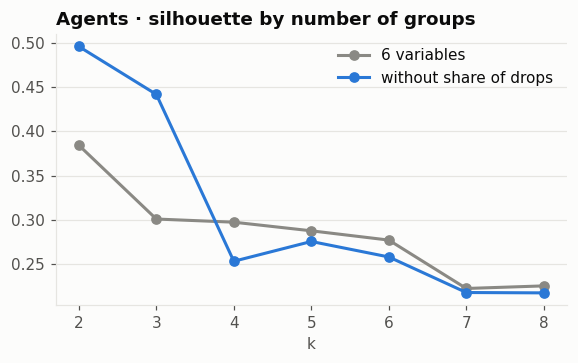

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(c.index, c['with frac_caidas'], color=MUTED, marker='o', label='6 variables')
ax.plot(c.index, c['without frac_caidas'], color=BLUE, marker='o', label='without share of drops')
ax.set_title('Agents · silhouette by number of groups'); ax.set_xlabel('k'); ax.legend()
plt.show()

In [4]:
g = prof.groupby('grupo_sin_k3')[['log_tamano', 'estacionalidad', 'volatilidad', 'tendencia_anual']].median()
g.insert(0, 'agents', prof['grupo_sin_k3'].value_counts().sort_index())
g

,agents,log_tamano,estacionalidad,volatilidad,tendencia_anual
grupo_sin_k3,,,,,
0,706,3.4,-5.8e-03,7.7e-02,-5.6e-03
1,119,2.1,-1.0e-01,1.6e-01,2.0e-01
2,43,3.0,6.2e-01,1.9e-01,-1.5e-01


In [5]:
import json
rm = pd.DataFrame(json.load(open('../results/tp3_grupos_curva.json'))).set_index('k')
rm.round(2)

,silueta,davies_bouldin,ari_sube,ari_region
k,,,,
2,0.2,1.6,-1.0e-02,-1.0e-02
3,0.3,1.2,-1.0e-02,6.0e-02
4,0.3,1.3,-0.0e+00,1.4e-01
5,0.2,1.3,7.0e-02,1.8e-01
6,0.2,1.3,4.0e-02,2.2e-01
7,0.2,1.3,6.0e-02,2.3e-01
8,0.2,1.3,4.0e-02,2.0e-01


**Takeaways**

- Dropping the share of sharp drops (redundant with volatility) raises the silhouette from 0.30 to 0.44 with three groups of agents: 706 typical, 119 volatile and 43 large, very stable ones.
- The region-month groups follow geography and season (GBA vs the rest, first vs second half of the year), not the *up* / *down* label (adjusted Rand index ≈ 0).